In [21]:
from google.colab import drive
from pathlib import Path
import os
import json
import re
import subprocess
import shutil
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from IPython.display import display, Video

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/NBA_Tracking_Project")

CLIPS_DIR = ROOT / "datasets" / "tracking_test_v1" / "clips"

EVAL_DIR = ROOT / "outputs" / "tracking_evaluation_v1"
FRAMES_DIR = EVAL_DIR / "sample_frames"
CONTACT_DIR = EVAL_DIR / "contact_sheets"

EVAL_DIR.mkdir(parents=True, exist_ok=True)
FRAMES_DIR.mkdir(parents=True, exist_ok=True)
CONTACT_DIR.mkdir(parents=True, exist_ok=True)

assert ROOT.exists(), f"Progetto non trovato: {ROOT}"
assert CLIPS_DIR.exists(), f"Cartella clip non trovata: {CLIPS_DIR}"

print("Progetto:", ROOT)
print("Clip:", CLIPS_DIR)
print("Risultati:", EVAL_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Progetto: /content/drive/MyDrive/NBA_Tracking_Project
Clip: /content/drive/MyDrive/NBA_Tracking_Project/datasets/tracking_test_v1/clips
Risultati: /content/drive/MyDrive/NBA_Tracking_Project/outputs/tracking_evaluation_v1


In [29]:
def probe_video(path):
    command = [
        "ffprobe",
        "-v", "error",
        "-select_streams", "v:0",
        "-show_entries",
        "stream=codec_name,width,height,avg_frame_rate,nb_frames:"
        "format=duration,format_name",
        "-of", "json",
        str(path)
    ]

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    if result.returncode != 0:
        return None

    try:
        return json.loads(result.stdout)
    except json.JSONDecodeError:
        return None


videos = []

for path in sorted(CLIPS_DIR.iterdir()):
    if not path.is_file():
        continue

    info = probe_video(path)

    if info and info.get("streams"):
        videos.append(path)

print(f"Video trovati: {len(videos)}")

for i, path in enumerate(videos, 1):
    print(f"{i:02d}. {path.name}")

if len(videos) != 9:
    print(
        f"\nATTENZIONE: erano previste 9 clip, "
        f"ma ne sono state trovate {len(videos)}."
    )

Video trovati: 7
01. clip_01.mov
02. clip_03.mov
03. clip_04.mov
04. clip_05.mov
05. clip_06.mov
06. clip_07.mov
07. clip_08.mov

ATTENZIONE: erano previste 9 clip, ma ne sono state trovate 7.


In [30]:
from fractions import Fraction

def parse_fps(value):
    try:
        return float(Fraction(str(value)))
    except (ValueError, ZeroDivisionError):
        return 0.0


records = []

for path in videos:
    info = probe_video(path)

    stream = info["streams"][0]
    fmt = info.get("format", {})

    fps = parse_fps(stream.get("avg_frame_rate", "0/1"))
    duration = float(fmt.get("duration", 0) or 0)

    frame_count = stream.get("nb_frames")

    try:
        frame_count = int(frame_count)
    except (ValueError, TypeError):
        frame_count = round(duration * fps)

    width = int(stream.get("width", 0))
    height = int(stream.get("height", 0))

    records.append({
        "clip": path.stem,
        "file_name": path.name,
        "path": str(path),
        "codec": stream.get("codec_name", "unknown"),
        "container": fmt.get("format_name", "unknown"),
        "fps": round(fps, 3),
        "duration_s": round(duration, 3),
        "frames": frame_count,
        "width": width,
        "height": height,
        "resolution": f"{width}x{height}",
        "size_mb": round(path.stat().st_size / 1024**2, 2)
    })

metadata_df = pd.DataFrame(records)

assert not metadata_df.empty, "Nessun video valido trovato."

display(metadata_df[
    [
        "clip", "codec", "fps",
        "duration_s", "frames",
        "resolution", "size_mb"
    ]
])

metadata_df.to_csv(
    EVAL_DIR / "video_metadata.csv",
    index=False
)

print("\nDurata totale:",
      round(metadata_df.duration_s.sum(), 2), "secondi")

print("Frame totali:", metadata_df.frames.sum())

,clip,codec,fps,duration_s,frames,resolution,size_mb
0,clip_01,h264,28.997,3.690,107,854x480,0.86
1,clip_03,h264,28.992,4.863,141,854x480,1.14
2,clip_04,h264,28.997,4.587,133,854x480,1.09
3,clip_05,h264,29.005,10.550,306,854x480,2.31
4,clip_06,h264,28.997,10.415,302,854x480,2.29
5,clip_07,h264,28.993,4.967,144,854x480,1.10
6,clip_08,h264,29.007,6.447,187,854x480,1.42



Durata totale: 45.52 secondi
Frame totali: 1320


In [31]:
quality_records = []

for path in videos:
    cap = cv2.VideoCapture(str(path))

    decoded_frames = 0
    black_frames = 0
    very_dark_frames = 0
    frame_differences = []

    previous_gray = None

    while True:
        ok, frame = cap.read()

        if not ok:
            break

        decoded_frames += 1

        gray = cv2.cvtColor(
            frame, cv2.COLOR_BGR2GRAY
        )

        mean_brightness = float(gray.mean())

        if mean_brightness < 5:
            black_frames += 1

        if mean_brightness < 25:
            very_dark_frames += 1

        if previous_gray is not None:
            diff = float(
                cv2.absdiff(gray, previous_gray).mean()
            )
            frame_differences.append(diff)

        previous_gray = gray

    cap.release()

    quality_records.append({
        "clip": path.name,
        "decoded_frames": decoded_frames,
        "black_frames": black_frames,
        "very_dark_frames": very_dark_frames,
        "mean_frame_difference": (
            np.mean(frame_differences)
            if frame_differences else np.nan
        ),
        "max_frame_difference": (
            np.max(frame_differences)
            if frame_differences else np.nan
        ),
        "readable": decoded_frames > 0
    })

quality_df = pd.DataFrame(quality_records)

display(quality_df)

quality_df.to_csv(
    EVAL_DIR / "video_quality_check.csv",
    index=False
)

,clip,decoded_frames,black_frames,very_dark_frames,mean_frame_difference,max_frame_difference,readable
0,clip_01.mov,107,0,0,5.882862,12.662083,True
1,clip_03.mov,141,0,0,11.266718,20.629242,True
2,clip_04.mov,133,0,0,9.908578,24.546553,True
3,clip_05.mov,306,0,0,7.195456,22.190674,True
4,clip_06.mov,302,0,0,18.187338,68.770040,True
5,clip_07.mov,144,0,0,9.396353,22.351893,True
6,clip_08.mov,187,0,0,15.974471,28.294440,True


In [32]:
sample_records = []

for path in videos:
    cap = cv2.VideoCapture(str(path))

    n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if n_frames <= 0:
        cap.release()
        continue

    indices = sorted(set(
        np.linspace(
            0,
            n_frames - 1,
            num=min(5, n_frames),
            dtype=int
        ).tolist()
    ))

    for sample_idx, frame_idx in enumerate(indices):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

        ok, frame = cap.read()

        if not ok:
            continue

        output_name = (
            f"{path.stem}_sample_{sample_idx:02d}"
            f"_frame_{frame_idx:05d}.jpg"
        )

        output_path = FRAMES_DIR / output_name

        cv2.imwrite(
            str(output_path),
            frame,
            [cv2.IMWRITE_JPEG_QUALITY, 95]
        )

        sample_records.append({
            "clip": path.name,
            "frame": int(frame_idx),
            "sample_path": str(output_path)
        })

    cap.release()

samples_df = pd.DataFrame(sample_records)

samples_df.to_csv(
    EVAL_DIR / "sample_frames_manifest.csv",
    index=False
)

print(f"Frame campionati: {len(samples_df)}")
display(samples_df.head(10))

Frame campionati: 35


,clip,frame,sample_path
0,clip_01.mov,0,/content/drive/MyDrive/NBA_Tracking_Project/ou...
1,clip_01.mov,26,/content/drive/MyDrive/NBA_Tracking_Project/ou...
2,clip_01.mov,53,/content/drive/MyDrive/NBA_Tracking_Project/ou...
3,clip_01.mov,79,/content/drive/MyDrive/NBA_Tracking_Project/ou...
4,clip_01.mov,106,/content/drive/MyDrive/NBA_Tracking_Project/ou...
5,clip_03.mov,0,/content/drive/MyDrive/NBA_Tracking_Project/ou...
6,clip_03.mov,35,/content/drive/MyDrive/NBA_Tracking_Project/ou...
7,clip_03.mov,70,/content/drive/MyDrive/NBA_Tracking_Project/ou...
8,clip_03.mov,105,/content/drive/MyDrive/NBA_Tracking_Project/ou...
9,clip_03.mov,140,/content/drive/MyDrive/NBA_Tracking_Project/ou...



 clip_01.mov


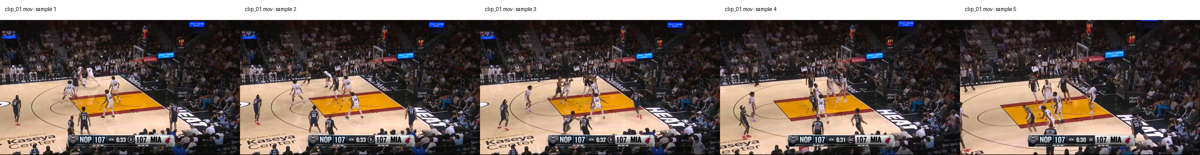


 clip_03.mov


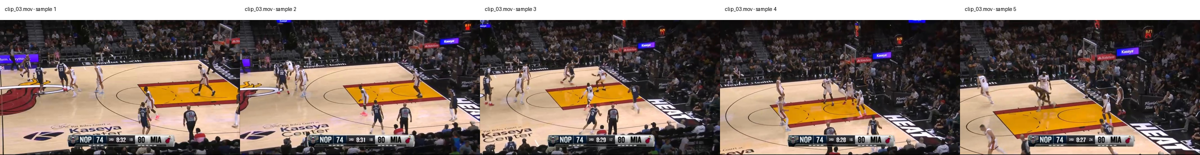


 clip_04.mov


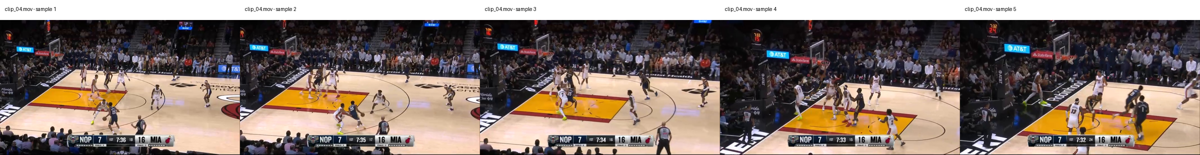


 clip_05.mov


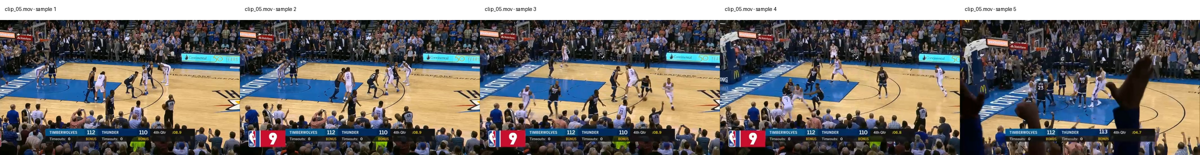


 clip_06.mov


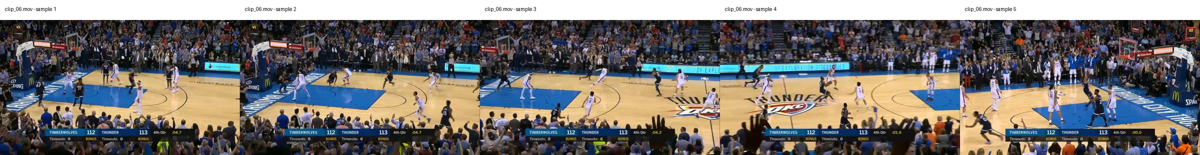


 clip_07.mov


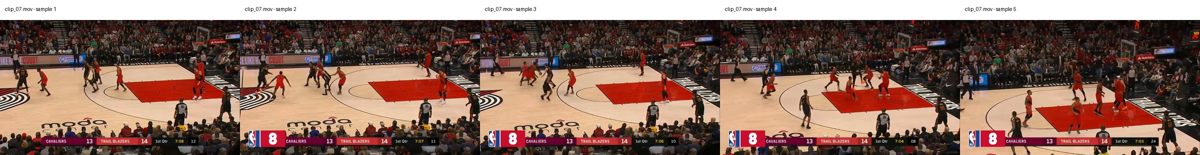


 clip_08.mov


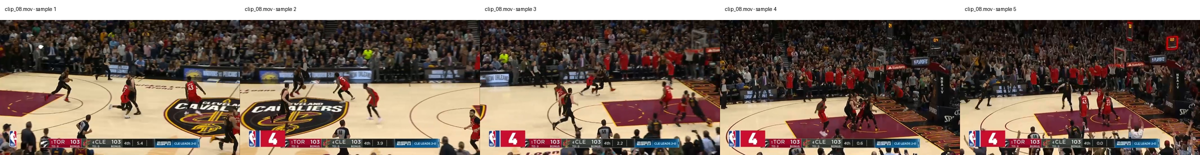

In [33]:
from PIL import Image, ImageDraw, ImageFont

for clip_name, group in samples_df.groupby("clip"):

    images = []

    for sample_path in group.sample_path:
        with Image.open(sample_path) as img:
            im = img.convert("RGB")
            im.thumbnail((480, 270))

            canvas = Image.new(
                "RGB", (480, 270), "black"
            )

            x = (480 - im.width) // 2
            y = (270 - im.height) // 2

            canvas.paste(im, (x, y))
            images.append(canvas)

    if not images:
        continue

    sheet = Image.new(
        "RGB",
        (480 * len(images), 310),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for i, img in enumerate(images):
        sheet.paste(img, (i * 480, 40))
        draw.text(
            (i * 480 + 10, 12),
            f"{clip_name} - sample {i+1}",
            fill="black"
        )

    output_path = CONTACT_DIR / f"{Path(clip_name).stem}_sheet.jpg"
    sheet.save(output_path, quality=90)

    print("\n", clip_name)
    display(sheet.resize(
        (min(sheet.width, 1200),
         round(sheet.height * min(sheet.width, 1200) / sheet.width))
    ))

In [34]:
def sha256_file(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


manifest_records = []

for i, path in enumerate(videos, start=1):
    row = metadata_df[
        metadata_df["path"] == str(path)
    ].iloc[0]

    manifest_records.append({
        "clip_id": f"clip_{i:02d}",
        "file_name": path.name,
        "original_path": str(path),
        "fps": float(row["fps"]),
        "duration_s": float(row["duration_s"]),
        "frames": int(row["frames"]),
        "resolution": row["resolution"],
        "sha256": sha256_file(path),
        "source_game": "",
        "source_url": "",
        "source_timestamp": "",
        "scenario": "",
        "training_overlap_checked": False,
        "annotation_status": "not_started"
    })

manifest_df = pd.DataFrame(manifest_records)

manifest_df.to_csv(
    EVAL_DIR / "test_set_manifest.csv",
    index=False
)

manifest_df.to_json(
    EVAL_DIR / "test_set_manifest.json",
    orient="records",
    indent=2
)

display(manifest_df[
    [
        "clip_id", "file_name", "fps",
        "duration_s", "resolution",
        "scenario", "annotation_status"
    ]
])

print("\nManifest salvato.")
print(EVAL_DIR / "test_set_manifest.csv")

,clip_id,file_name,fps,duration_s,resolution,scenario,annotation_status
0,clip_01,clip_01.mov,28.997,3.690,854x480,,not_started
1,clip_02,clip_03.mov,28.992,4.863,854x480,,not_started
2,clip_03,clip_04.mov,28.997,4.587,854x480,,not_started
3,clip_04,clip_05.mov,29.005,10.550,854x480,,not_started
4,clip_05,clip_06.mov,28.997,10.415,854x480,,not_started
5,clip_06,clip_07.mov,28.993,4.967,854x480,,not_started
6,clip_07,clip_08.mov,29.007,6.447,854x480,,not_started



Manifest salvato.
/content/drive/MyDrive/NBA_Tracking_Project/outputs/tracking_evaluation_v1/test_set_manifest.csv


In [36]:

from pathlib import Path
import pandas as pd
import hashlib

MANIFEST_PATH = EVAL_DIR / "test_set_manifest.csv"

old_manifest = (
    pd.read_csv(MANIFEST_PATH, keep_default_na=False)
    if MANIFEST_PATH.exists()
    else pd.DataFrame()
)

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

records = []

for path in sorted(CLIPS_DIR.iterdir()):
    if not path.is_file():
        continue

    info = probe_video(path)
    if not info or not info.get("streams"):
        continue

    stream = info["streams"][0]
    fmt = info.get("format", {})

    fps = parse_fps(stream.get("avg_frame_rate", "0/1"))
    duration = float(fmt.get("duration", 0) or 0)

    clip_id = path.stem
    previous = old_manifest[
        old_manifest["file_name"] == path.name
    ] if "file_name" in old_manifest.columns else pd.DataFrame()

    previous_row = (
        previous.iloc[0].to_dict()
        if not previous.empty else {}
    )

    records.append({
        "clip_id": clip_id,
        "file_name": path.name,
        "original_path": str(path),
        "fps": fps,
        "duration_s": duration,
        "frames": int(stream.get("nb_frames") or round(duration * fps)),
        "resolution": f"{stream.get('width')}x{stream.get('height')}",
        "sha256": sha256_file(path),
        "source_game": previous_row.get("source_game", ""),
        "source_url": previous_row.get("source_url", ""),
        "source_timestamp": previous_row.get("source_timestamp", ""),
        "scenario": (
            "camera_pan_full_court"
            if clip_id == "clip_06"
            else previous_row.get("scenario", "")
        ),
        "training_overlap_checked": previous_row.get(
            "training_overlap_checked", False
        ),
        "annotation_status": previous_row.get(
            "annotation_status", "not_started"
        )
    })

manifest_df = pd.DataFrame(records)

assert len(manifest_df) == 7, (
    f"Attese 7 clip, trovate {len(manifest_df)}. "
    "Controlla i file nella cartella."
)

assert manifest_df["sha256"].nunique() == 7, (
    "Sono ancora presenti file duplicati identici."
)

manifest_df.to_csv(MANIFEST_PATH, index=False)

manifest_df.to_json(
    EVAL_DIR / "test_set_manifest.json",
    orient="records",
    indent=2
)

display(manifest_df[
    ["clip_id", "duration_s", "frames", "resolution", "scenario"]
])

print("\nDataset aggiornato correttamente.")
print("Clip:", len(manifest_df))
print("Frame:", manifest_df["frames"].sum())
print("Durata:", round(manifest_df["duration_s"].sum(), 2), "secondi")


,clip_id,duration_s,frames,resolution,scenario
0,clip_01,3.690000,107,854x480,
1,clip_03,4.863333,141,854x480,
2,clip_04,4.586667,133,854x480,
3,clip_05,10.550000,306,854x480,
4,clip_06,10.415000,302,854x480,camera_pan_full_court
5,clip_07,4.966667,144,854x480,
6,clip_08,6.446667,187,854x480,



Dataset aggiornato correttamente.
Clip: 7
Frame: 1320
Durata: 45.52 secondi
